In [1]:
import numpy as np
import pandas as pd 

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv("Telco-Cust.csv")
df=df.drop(["customerID"], axis=1)

In [3]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df.head()
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [4]:
class_counts = df["Churn"].value_counts(normalize=True)*100
print(f'Баланс классов:\n0 (Остался): {class_counts[0]:.1f}%\n1 (Ушёл): {class_counts[1]:.1f}%')

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(df.columns)

Баланс классов:
0 (Остался): 73.5%
1 (Ушёл): 26.5%
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


Мы можем наблюдать, что по балансу классов большинство людей предпочло остаться.

In [5]:
numeric_features = ['tenure', 'SeniorCitizen', 'MonthlyCharges',]
categorical_features = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges',]

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

#Ветка 2
categorical_transforer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

#объединяет ветки 1 и 2
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transforer, categorical_features)
    ]
)

#Итоговый конвейер: Переработка -> Модель
clf_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", KNeighborsClassifier())]
)

#сетка поиска
parem_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform", "distance"],
}

#5-fold кросс валидация
cv_startegy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Сбор всего в GridSearchCv, с проверкой ROC-AUC
grid_search=GridSearchCV(
    estimator=clf_pipeline,
    param_grid=parem_grid,
    cv=cv_startegy,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
#извлекаем лучшую модeль
best_model = grid_search.best_estimator_
print(f'\Лучшие парамеры алгоритма: {grid_search.best_params_}')


\Лучшие парамеры алгоритма: {'classifier__n_neighbors': 9, 'classifier__weights': 'uniform'}


Были подобраны лучшие показатели для обучения модели

In [6]:
# предсказание 0 или 1
y_pred = best_model.predict(X_test)

#предсказание вероятностей от 0.0 до 1.0
y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Матрица ошибок ---")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно орицательные (TN - человек остался, мы предсказали это){conf_matrix[0][0]}")
print(f"Ложно положительные (FP - человек остался, мы не предсказали это){conf_matrix[0][1]}")
print(f"Ложно орицательные (FN - человек ушёл, мы это не предсказали){conf_matrix[1][0]}")
print(f"Истинно положительные (TP - человек ушёл, мы это предсказали){conf_matrix[1][1]}")

print("---Отчет по метрикам---")
print(classification_report(y_test, y_pred, target_names=["Остался (0)", "Ушёл (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

--- Матрица ошибок ---
Истинно орицательные (TN - человек остался, мы предсказали это)878
Ложно положительные (FP - человек остался, мы не предсказали это)157
Ложно орицательные (FN - человек ушёл, мы это не предсказали)163
Истинно положительные (TP - человек ушёл, мы это предсказали)211
---Отчет по метрикам---
              precision    recall  f1-score   support

 Остался (0)       0.84      0.85      0.85      1035
    Ушёл (1)       0.57      0.56      0.57       374

    accuracy                           0.77      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.77      0.77      0.77      1409

Площадь под кривой ROC-AUC: 0.8072


Данная модель показывает высокое качество, однако модель не хватает достаточно данных и не может предсказать кто уйдёт. 

In [11]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
df_reg = df.copy()
X_reg = df_reg[["tenure", "SeniorCitizen"]]
y_reg = df_reg["MonthlyCharges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_pipline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3,30),
    "knn_reg__weights": ["uniform", "distance"],
}
random_search = RandomizedSearchCV(
    estimator=reg_pipline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {random_search.best_params_}')


Лучшие параметры алгоритмы: {'knn_reg__weights': 'uniform', 'knn_reg__n_neighbors': np.int64(29)}


Выбраны лучшие параметры, также было замечано, что randomize справился с этой задачей эффективнее

In [ ]:
y_pred_r = best_reg.predict(X_test_r)

def smape(y_test, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_test) / (np.abs(y_test) + np.abs(y_pred))
    )
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("--- Отчет по метрикам регресии ---")
print(f"MSE (квадратные $) {mse:,.0f}")
print(f"RMSE ($) {rmse:,.2f}")
print(f"MAE (средняя ошибка) {mae:,.2f}")
print(f"SMAPE (Ошибка в % $){smape_value:,.2f}")


--- Отчет по метрикам регресии ---
MSE (квадратные $) 853
RMSE ($) 29.20
MAE (средняя ошибка) 24.74
SMAPE (Ошибка в % $)43.64


Текущая модель регрессии работает очень плохо и дает слишком грубые предсказания для реального использования. Ошибка в среднем составляет около 25 долларов на каждый прогноз, а относительная погрешность достигает критических 43,6%, что для финансовых расчетов является недопустимо большим отклонением.

Text(0, 0.5, 'Кол-во клиентов')

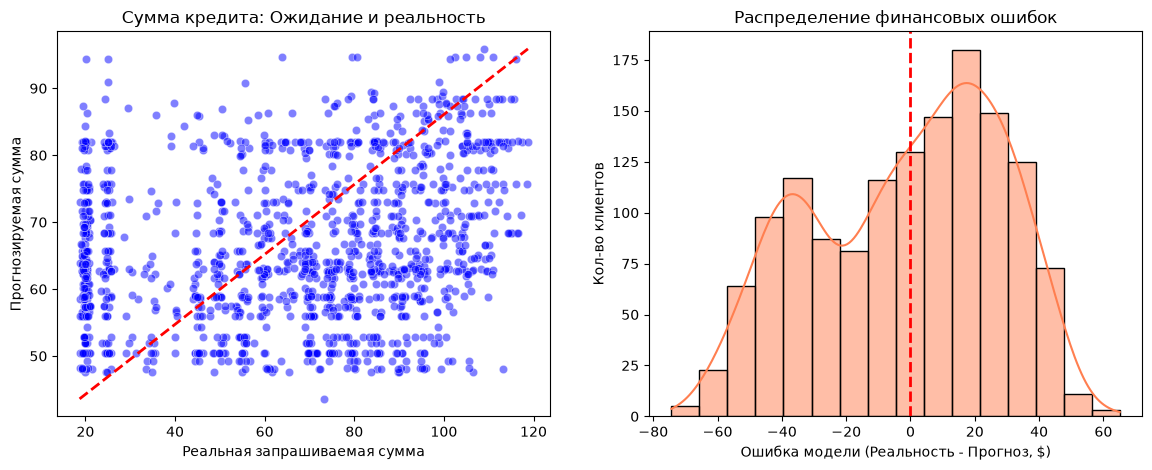

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2,figsize=(14,5))

#1 график
sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color='blue', ax=axes[0])
axes[0].plot(
    [y_test_r.min(), y_test_r.max()], [y_pred_r.min(), y_pred_r.max()], 'r--', lw=2
)
axes[0].set_title("Ежемесячные траты")
axes[0].set_xlabel("Реальные ежемесячные траты")
axes[0].set_ylabel("Прогнозируемые ежемесячные траты")

#2 график: распределение ошибок
residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle="--", lw=2)
axes[1].set_title("Распределение финансовых ошибок")
axes[1].set_xlabel("Ошибка модели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Кол-во клиентов")

Данная модель работает неэффективно и демонстрирует явные систематические искажения в прогнозах. 
Главная проблема заключается в том, что алгоритм не в состояни точно просчитать потеряем ли мы клиента или нет, из-за чего пик распределения ошибок смещен в положительную сторону и недостаточно информации.
Невозожно предсказать сумму ежемесячных трат на основе данных, которые  были использованы